<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/week5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [ ]:
# Input data: [x1, x2]
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1],
    [0.1, 0.2],
    [0.2, 0.9],
    [0.8, 0.1],
    [0.9, 0.8]
])

# Labels
y = np.array([
    [0],
    [1],
    [1],
    [0],
    [0],
    [1],
    [1],
    [0]
])

In [ ]:
print("Input matrix X:")
print(X)

print("\nShape of X:")
print(X.shape)

# Select first data point as a vector
v = X[0]

print("\nFirst vector:")
print(v)

# Vector magnitude
magnitude = np.linalg.norm(v)

print("\nMagnitude:")
print(magnitude)

Input matrix X:
[[0.  0. ]
 [0.  1. ]
 [1.  0. ]
 [1.  1. ]
 [0.1 0.2]
 [0.2 0.9]
 [0.8 0.1]
 [0.9 0.8]]

Shape of X:
(8, 2)

First vector:
[0. 0.]

Magnitude:
0.0


In [ ]:
a = np.array([2, 3])
b = np.array([4, 5])

dot_product = np.dot(a, b)

print("Vector a:", a)
print("Vector b:", b)
print("Dot product:", dot_product)

Vector a: [2 3]
Vector b: [4 5]
Dot product: 23


In [ ]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [ ]:
def sigmoid_derivative(x):
    return sigmoid(x) * (1 - sigmoid(x))

In [ ]:
input_size = 2
hidden_size = 4
output_size = 1

W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)

W1 shape: (2, 4)
W2 shape: (4, 1)


In [ ]:
def forward(X):

    # First layer
    Z1 = np.dot(X, W1) + b1

    # Activation
    A1 = sigmoid(Z1)

    # Output layer
    Z2 = np.dot(A1, W2) + b2

    # Final prediction
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2

In [ ]:
def loss_function(y, predictions):

    epsilon = 1e-8

    loss = -np.mean(
        y * np.log(predictions + epsilon) +
        (1-y) * np.log(1-predictions + epsilon)
    )

    return loss

In [ ]:
def backward(X, y, Z1, A1, Z2, A2):

    m = len(X)

    # Output layer gradient
    dZ2 = A2 - y

    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Backpropagate to hidden layer
    dA1 = np.dot(dZ2, W2.T)

    dZ1 = dA1 * sigmoid_derivative(Z1)

    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return dW1, db1, dW2, db2

In [ ]:
learning_rate = 1.0
epochs = 5000

loss_history = []

for epoch in range(epochs):

    # Forward pass
    Z1, A1, Z2, predictions = forward(X)

    # Calculate loss
    loss = loss_function(y, predictions)

    # Backpropagation
    dW1, db1, dW2, db2 = backward(
        X, y, Z1, A1, Z2, predictions
    )

    # Update weights
    W1[:] = W1 - learning_rate * dW1
    b1[:] = b1 - learning_rate * db1

    W2[:] = W2 - learning_rate * dW2
    b2[:] = b2 - learning_rate * db2

    loss_history.append(loss)

    if epoch % 500 == 0:
        print("Epoch:", epoch, "Loss:", loss)

Epoch: 0 Loss: 0.760601178696566
Epoch: 500 Loss: 0.17487695206000547
Epoch: 1000 Loss: 0.0193344241177503
Epoch: 1500 Loss: 0.008348627966305162
Epoch: 2000 Loss: 0.005079968772399366
Epoch: 2500 Loss: 0.003582075959184686
Epoch: 3000 Loss: 0.0027393656483789327
Epoch: 3500 Loss: 0.002204745304432268
Epoch: 4000 Loss: 0.001837731279289328
Epoch: 4500 Loss: 0.0015713242361287904


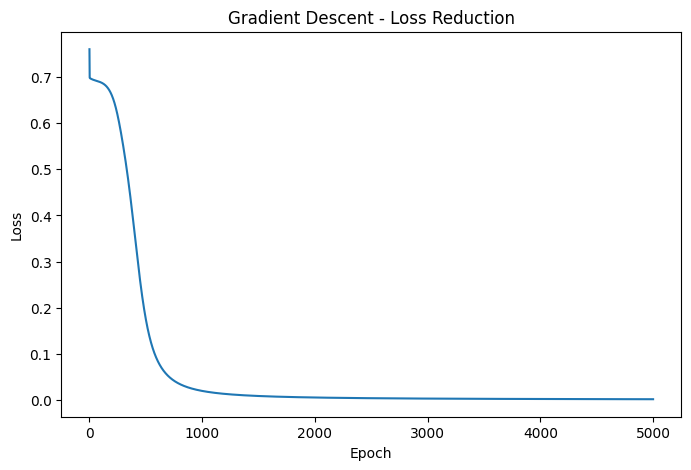

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Gradient Descent - Loss Reduction")

plt.show()

In [ ]:
_, _, _, predictions = forward(X)

print("Actual:")
print(y.flatten())

print("\nPredicted probabilities:")
print(predictions.flatten())

print("\nPredicted classes:")
print((predictions > 0.5).astype(int).flatten())

Actual:
[0 1 1 0 0 1 1 0]

Predicted probabilities:
[4.67348982e-04 9.99405966e-01 9.99065900e-01 9.55234160e-04
 7.98016410e-04 9.97900969e-01 9.97993194e-01 3.09299900e-03]

Predicted classes:
[0 1 1 0 0 1 1 0]


In [ ]:
predicted_classes = (predictions > 0.5).astype(int)

accuracy = np.mean(predicted_classes == y) * 100

print("Accuracy:", accuracy, "%")

Accuracy: 100.0 %


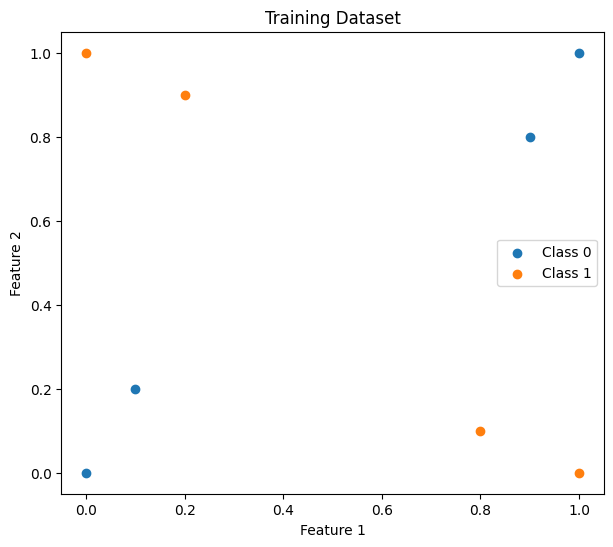

In [ ]:
plt.figure(figsize=(7,6))

plt.scatter(
    X[y.flatten() == 0, 0],
    X[y.flatten() == 0, 1],
    label="Class 0"
)

plt.scatter(
    X[y.flatten() == 1, 0],
    X[y.flatten() == 1, 1],
    label="Class 1"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Training Dataset")
plt.legend()

plt.show()

In [ ]:
A = np.array([
    [4, 2],
    [1, 3]
])

eigenvalues, eigenvectors = np.linalg.eig(A)

print("Matrix:")
print(A)

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Matrix:
[[4 2]
 [1 3]]

Eigenvalues:
[5. 2.]

Eigenvectors:
[[ 0.89442719 -0.70710678]
 [ 0.4472136   0.70710678]]


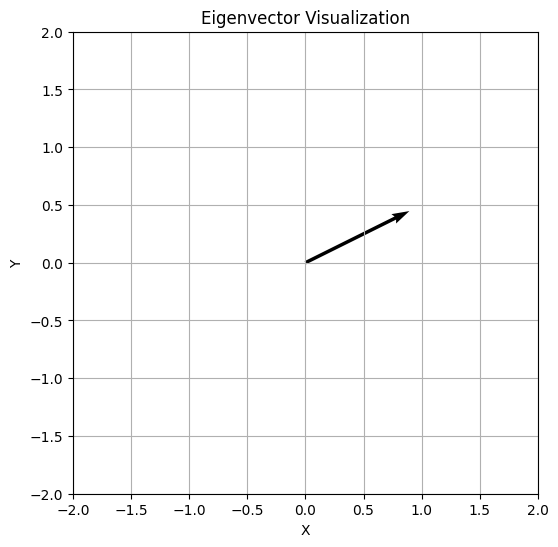

In [ ]:
v = eigenvectors[:, 0]

plt.figure(figsize=(6,6))

plt.quiver(
    0, 0,
    v[0], v[1],
    angles='xy',
    scale_units='xy',
    scale=1
)

plt.xlim(-2, 2)
plt.ylim(-2, 2)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Eigenvector Visualization")
plt.grid()

plt.show()